# DoorDash — Predicting Delivery Time

**Goal:** predict `delivery_minutes` from what is known when an order is placed, evaluate honestly (MAE, minutes), explain what makes deliveries slow, and predict the held-out test orders.

**This is the only file needed.** Everything — EDA, modelling, charts, explanations — lives in this notebook. The final cell writes the one required output, `predictions.csv`.

**Headline result:** HistGradientBoosting, 5-fold CV **MAE = 3.27 min** vs **7.73 min** for a flat-average baseline (−58%).

**Enhancements (Section 8):** a 75th-percentile "promise" model with coverage evaluation, a very-late-risk classifier, SHAP explanations, and an honestly *rejected* restaurant target-encoding experiment — plus a companion Streamlit demo (`app.py`).

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

pd.set_option("display.width", 120)
RANDOM_STATE, TARGET_CAP = 42, 60   # TARGET_CAP explained in Section 2

train = pd.read_csv("deliveries_train.csv", parse_dates=["order_placed_at"])
test  = pd.read_csv("deliveries_test.csv",  parse_dates=["order_placed_at"])
print(train.shape, test.shape)
train.head(3)

(8000, 13) (2000, 12)


,order_id,order_placed_at,restaurant_id,cuisine,restaurant_avg_prep_minutes,city_zone,distance_km,items_count,order_subtotal,courier_vehicle,courier_trips_completed,weather,delivery_minutes
0,700001,2025-03-01 10:00:00,10,pizza,12.9,suburbs_north,2.2,2,19.24,scooter,50.0,cloudy,29
1,700003,2025-03-01 11:06:00,5,mexican,12.4,uptown,5.3,1,8.36,bike,1255.0,clear,36
2,700004,2025-03-01 11:15:00,59,pizza,11.7,suburbs_south,2.6,3,27.38,scooter,276.0,clear,31


## 1. Explore the data

Train/test span the same period (Mar–Aug 2025) with near-identical feature distributions, and there are no duplicate or overlapping `order_id`s and no unseen categories in test — so the split is randomly interleaved in time, which later justifies shuffled cross-validation (with a chronological split as a robustness check).

In [2]:
print("train period:", train.order_placed_at.min(), "->", train.order_placed_at.max())
print("test  period:", test.order_placed_at.min(), "->", test.order_placed_at.max())
print("duplicate ids:", train.order_id.duplicated().sum(), "| id overlap train/test:",
      len(set(train.order_id) & set(test.order_id)))
print("\nMissing values (train):"); print(train.isna().sum()[train.isna().sum()>0])
print("\nTarget summary:"); print(train.delivery_minutes.describe(
      percentiles=[.5,.9,.95,.99]).round(2).to_string())
print(f"skew = {train.delivery_minutes.skew():.2f}")

train period: 2025-03-01 10:00:00 -> 2025-08-31 23:42:00
test  period: 2025-03-01 11:04:00 -> 2025-08-31 20:42:00
duplicate ids: 0 | id overlap train/test: 0

Missing values (train):
courier_trips_completed    329
weather                    228
dtype: int64

Target summary:
count    8000.00
mean       32.05
std        11.14
min         8.00
50%        31.00
90%        44.00
95%        49.00
99%        62.00
max       139.00
skew = 2.61


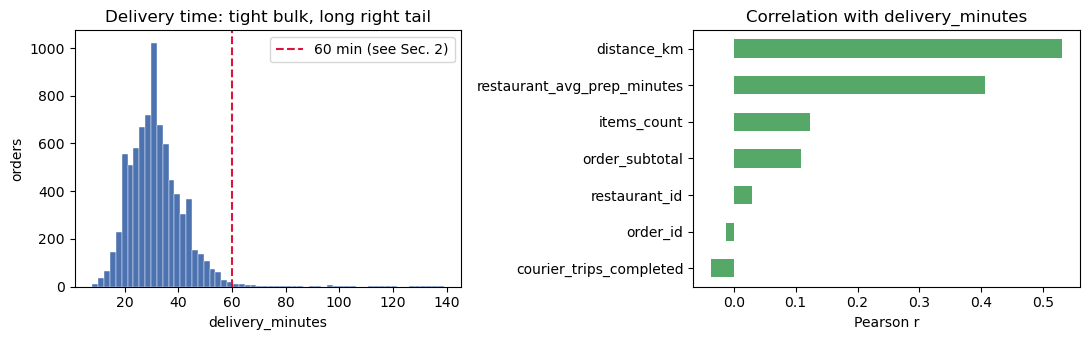

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train.delivery_minutes, bins=60, color="#4C72B0", edgecolor="white", lw=.3)
axes[0].axvline(TARGET_CAP, color="crimson", ls="--", label="60 min (see Sec. 2)")
axes[0].set(title="Delivery time: tight bulk, long right tail", xlabel="delivery_minutes", ylabel="orders")
axes[0].legend()
num_corr = train.select_dtypes(include=np.number).corr()["delivery_minutes"].drop("delivery_minutes")
num_corr.sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set(title="Correlation with delivery_minutes", xlabel="Pearson r")
plt.tight_layout(); plt.show()

In [4]:
# How each factor relates to delivery time (raw group means)
for c in ["cuisine", "city_zone", "courier_vehicle", "weather"]:
    print(train.groupby(c).delivery_minutes.agg(["mean","count"]).round(1).sort_values("mean").to_string(), "\n")
train.assign(hour=train.order_placed_at.dt.hour).groupby("hour").delivery_minutes.mean().round(1)

         mean  count
cuisine             
salads   25.0    946
mexican  28.6    951
burgers  29.0    488
chinese  32.0    801
thai     32.7   1500
pizza    32.8   1330
sushi    35.3    775
indian   37.8   1209 

               mean  count
city_zone                 
downtown       28.2   2431
midtown        30.9   2185
uptown         31.1   1530
suburbs_south  38.3   1068
suburbs_north  40.4    786 

                 mean  count
courier_vehicle             
scooter          31.0   3149
car              32.7   2284
bike             32.8   2567 

            mean  count
weather                
cloudy      31.3   1828
clear       31.4   4522
rain        34.2   1011
heavy_rain  36.9    411 



hour
10    28.4
11    33.4
12    32.9
13    33.8
14    29.6
15    29.7
16    29.5
17    30.1
18    33.8
19    33.1
20    32.9
21    30.3
22    29.1
23    30.3
Name: delivery_minutes, dtype: float64

**What EDA shows**

| Factor | Pattern |
|---|---|
| `distance_km` | Strongest signal (r=0.53): mean 24 min at ≤1 km → 50 min at >10 km |
| `restaurant_avg_prep_minutes` | r=0.41: ~24 min for fast kitchens → 40 min for 20+ min prep |
| `city_zone` | Suburbs ~39–40 vs downtown 28 min — but suburbs average ~6.5 km vs 2.0 km downtown (zone ≈ distance) |
| `cuisine` | Indian 37.8 / sushi 35.3 vs salads 25.0 — mostly prep time in disguise (sushi/Indian ≈18 min avg prep, salads ≈8) |
| `weather` | heavy_rain 36.9, rain 34.2 vs clear/cloudy ≈31.4 |
| Time | Lunch (11–13) & dinner (18–20) ≈33.3 vs 29.7 off-peak; day-of-week almost flat |
| `items_count` | 30.6 min (1 item) → 37.3 (8 items) |
| `courier_trips_completed` | Weak: novices ≈32.8 vs 1,000+ trips ≈30.4 |
| `order_subtotal` | Weak (r=0.11); per-item subtotal r≈0.00 once items are counted |

## 2. Data quality, extremes, missing values — and leakage control

**Three problems found:**

1. **Contaminated target tail.** 98.9% of orders are ≤60 min (p99=62) yet the max is 139, and the histogram falls off a cliff after ~60. The 37 orders >90 min are *feature-identical* to normal orders (mean distance 3.62 vs 3.58 km, prep 14.1 vs 13.8, same weather mix) — nothing knowable at order time distinguishes them. They look like accidents/breakdowns: real, but unpredictable surprises.
2. **Absurd courier experience.** `courier_trips_completed`: median 147, max **45,151** (p99=3,232) — logging errors, unusable raw.
3. **`restaurant_id` is a trap.** Every restaurant maps 1-to-1 to exactly one (`cuisine`, `city_zone`, `restaurant_avg_prep_minutes`) triple (within-restaurant prep std = 0), so the ID adds only memorisation. It is excluded — an ablation confirmed it *hurt* (Ridge CV MAE 3.398 with ID vs 3.366 without).

**Decisions**

- **Winsorise the training target at 60 min** (88 rows, 1.1% — rows kept, labels capped). All validation is still scored against the *original uncapped* labels, so the choice must pay for itself honestly (Section 5 shows it does; a median-loss model with no cap reaches the same MAE, corroborating it).
- **Missing values** (`weather` 2.9%, `courier_trips_completed` 4.1%; unrelated to the target, 31.8 vs 32.1 min): median / `"unknown"` imputation + missingness flags, fitted *inside* each CV fold via the pipeline — no leakage across folds.
- `courier_trips_completed` clipped at 5,000 and log-transformed; predictions clipped to the plausible range [8, 65].
- **Leakage audit:** only placement-time information is used (order time, restaurant attributes incl. *historical* avg prep, distance, basket, assigned courier's vehicle/experience, weather). `order_id` is never a feature; `delivery_minutes` is only the label.

In [5]:
print(f"orders >60 min: {(train.delivery_minutes>60).sum()} ({(train.delivery_minutes>60).mean()*100:.1f}%) | "
      f">90: {(train.delivery_minutes>90).sum()} | max: {train.delivery_minutes.max()}")
g = train.groupby("restaurant_id").agg(prep_std=("restaurant_avg_prep_minutes","std"),
                                       cuisines=("cuisine","nunique"), zones=("city_zone","nunique"))
print(f"restaurants whose cuisine/zone/prep ever varies: {(g.cuisines>1).sum()}, {(g.zones>1).sum()}, max prep std = {g.prep_std.max()}")
print("courier_trips_completed quantiles:"); print(train.courier_trips_completed.quantile([.5,.99,1.0]).to_string())

orders >60 min: 88 (1.1%) | >90: 37 | max: 139
restaurants whose cuisine/zone/prep ever varies: 0, 0, max prep std = 0.0
courier_trips_completed quantiles:
0.50      147.0
0.99     3231.7
1.00    45151.0


## 3. Feature engineering

From `order_placed_at`: `hour`, `dow`, `is_weekend`, `is_lunch` (11–13), `is_dinner` (18–20), `is_rush`, cyclical `hour_sin/cos`. Physically motivated combinations: `dist_x_wsev` (distance × weather severity — rain slows each kilometre, not a flat penalty), `prep_x_items` (big orders stress kitchens), `dist_sq`, `subtotal_per_item`, `log_trips`, ordinal `weather_sev` (clear 0 → heavy_rain 3). An explicit distance×vehicle feature was tried and rejected (CV MAE 3.286 vs 3.271 — trees find it; note bikes never take >6 km trips).

In [6]:
WEATHER_SEV = {"clear":0, "cloudy":1, "rain":2, "heavy_rain":3}
def add_features(df):
    d = df.copy(); ts = pd.to_datetime(d["order_placed_at"])
    d["hour"] = ts.dt.hour; d["dow"] = ts.dt.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    d["is_lunch"] = d["hour"].between(11,13).astype(int); d["is_dinner"] = d["hour"].between(18,20).astype(int)
    d["is_rush"] = ((d["is_lunch"]==1) | (d["is_dinner"]==1)).astype(int)
    d["hour_sin"] = np.sin(2*np.pi*d["hour"]/24); d["hour_cos"] = np.cos(2*np.pi*d["hour"]/24)
    d["weather_sev"] = d["weather"].map(WEATHER_SEV)
    d["dist_x_wsev"] = d["distance_km"] * d["weather_sev"].fillna(1)
    d["prep_x_items"] = d["restaurant_avg_prep_minutes"] * d["items_count"]
    d["dist_sq"] = d["distance_km"]**2
    d["subtotal_per_item"] = d["order_subtotal"] / d["items_count"]
    d["log_trips"] = np.log1p(d["courier_trips_completed"].clip(upper=5000))
    d["trips_missing"] = d["courier_trips_completed"].isna().astype(int)
    d["weather_missing"] = d["weather"].isna().astype(int)
    return d

train_f, test_f = add_features(train), add_features(test)
NUM = ["restaurant_avg_prep_minutes","distance_km","items_count","order_subtotal","hour","dow",
       "is_weekend","is_lunch","is_dinner","is_rush","hour_sin","hour_cos","weather_sev","log_trips",
       "trips_missing","weather_missing","subtotal_per_item","dist_x_wsev","prep_x_items","dist_sq"]
CAT = ["cuisine","city_zone","courier_vehicle","weather"]
FEATURES = NUM + CAT
X, y = train_f[FEATURES], train_f["delivery_minutes"].to_numpy(float)
y_train = np.minimum(y, TARGET_CAP)   # capped labels for TRAINING only
X_test = test_f[FEATURES]
print("features:", len(FEATURES), "| X:", X.shape, "| X_test:", X_test.shape)

features: 24 | X: (8000, 24) | X_test: (2000, 24)


## 4–5. Validation, baseline, and model comparison

Shuffled 5-fold CV (justified by the interleaved split), **MAE in minutes against the original uncapped labels** for every model, including the baseline. All models see identical features and capped training labels.

In [7]:
def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
def make_models():
    return {
      "Baseline (train median)": None,
      "Ridge (linear)": Pipeline([("pre", make_pre()), ("m", Ridge(alpha=10.0))]),
      "RandomForest": Pipeline([("pre", make_pre()), ("m", RandomForestRegressor(
          n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE))]),
      "HistGradientBoosting": Pipeline([("pre", make_pre()), ("m", HistGradientBoostingRegressor(
          learning_rate=0.03, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0,
          random_state=RANDOM_STATE))])}

kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
results, oof = [], {}
for name, model in make_models().items():
    if model is None:
        pred = np.zeros_like(y)
        for tr_idx, va_idx in kf.split(X): pred[va_idx] = np.median(y_train[tr_idx])
    else:
        pred = np.clip(cross_val_predict(model, X, y_train, cv=kf), 8, None); oof[name] = pred
    folds = [mean_absolute_error(y[va], pred[va]) for _, va in kf.split(X)]
    results.append({"model": name, "CV MAE": mean_absolute_error(y, pred), "fold std": np.std(folds)})
    print(f"{name:26s} CV MAE = {results[-1]['CV MAE']:.3f}  (fold std {results[-1]['fold std']:.3f})")
comparison = pd.DataFrame(results).sort_values("CV MAE"); comparison

Baseline (train median)    CV MAE = 7.729  (fold std 0.244)


Ridge (linear)             CV MAE = 3.366  (fold std 0.115)


RandomForest               CV MAE = 3.480  (fold std 0.129)


HistGradientBoosting       CV MAE = 3.271  (fold std 0.105)


,model,CV MAE,fold std
3,HistGradientBoosting,3.271140,0.105359
1,Ridge (linear),3.365867,0.115032
2,RandomForest,3.479900,0.129125
0,Baseline (train median),7.728500,0.243688


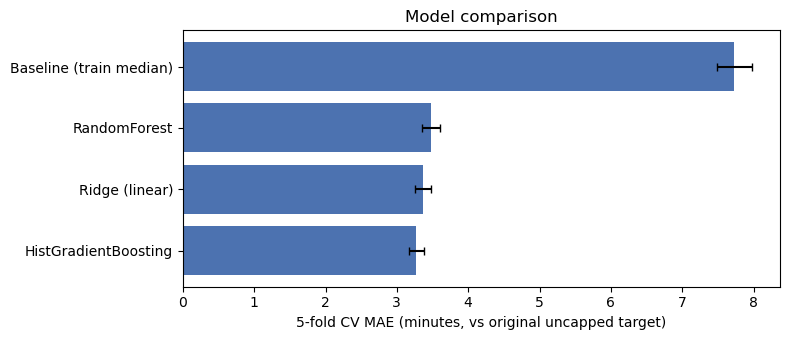

time-split MAE = 2.931  vs median baseline 7.508


train on capped (60)     hold-out MAE vs original y = 3.159


train uncapped           hold-out MAE vs original y = 3.367


In [8]:
c = comparison.sort_values("CV MAE")
plt.figure(figsize=(8,3.5)); plt.barh(c.model, c["CV MAE"], xerr=c["fold std"], color="#4C72B0", capsize=3)
plt.xlabel("5-fold CV MAE (minutes, vs original uncapped target)"); plt.title("Model comparison"); plt.tight_layout(); plt.show()

# Robustness 1: chronological split (train first 80% by date -> predict last 20%)
order = np.argsort(train_f.order_placed_at.to_numpy()); cut = int(.8*len(order))
m = make_models()["HistGradientBoosting"].fit(X.iloc[order[:cut]], y_train[order[:cut]])
p = np.clip(m.predict(X.iloc[order[cut:]]), 8, None)
print(f"time-split MAE = {mean_absolute_error(y[order[cut:]], p):.3f}  vs median baseline "
      f"{mean_absolute_error(y[order[cut:]], np.full(len(p), np.median(y_train[order[:cut]]))):.3f}")
# Robustness 2: does the 60-min cap actually help? (single 80/20 hold-out, HistGB, capped vs not)
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE)
for label, target in [("train on capped (60)", np.minimum(ytr, TARGET_CAP)), ("train uncapped", ytr)]:
    mm = make_models()["HistGradientBoosting"].fit(Xtr, target)
    print(f"{label:24s} hold-out MAE vs original y = {mean_absolute_error(yva, np.clip(mm.predict(Xva),8,None)):.3f}")

**Reading the results.** The linear Ridge is nearly as good as the trees — delivery time is mostly an additive physical process (prep + travel) with modest interactions. HistGradientBoosting still wins, captures the distance/vehicle/weather non-linearities, and is the chosen model. The chronological split (MAE ≈2.9) shows no temporal drift. The cap pays for itself on a clean hold-out, consistent with the full-CV check (HistGB uncapped: 3.46 → capped: 3.27) and with a no-cap median-loss model (3.27) — three routes, same conclusion.

## 6. What drives delivery time?

Permutation importance (held-out split: increase in MAE when one feature is shuffled), cross-checked with partial-dependence effects from the fitted model.

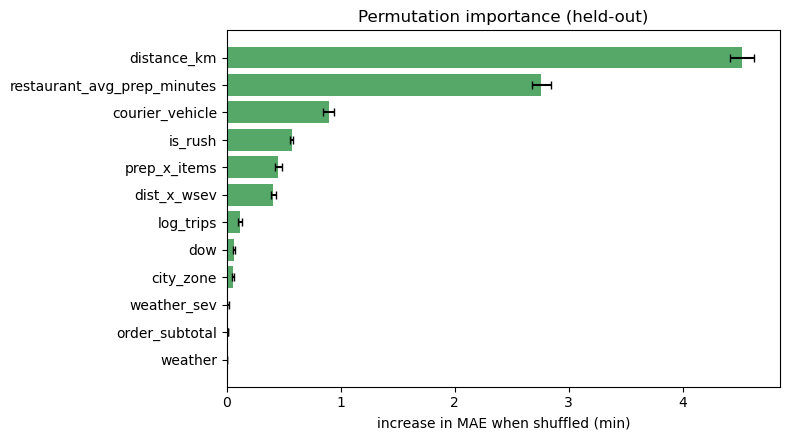

,feature,MAE increase,std
1,distance_km,4.521653,0.102495
0,restaurant_avg_prep_minutes,2.760219,0.085449
22,courier_vehicle,0.893280,0.046259
9,is_rush,0.567515,0.015818
18,prep_x_items,0.453095,0.028192
17,dist_x_wsev,0.407006,0.021235
13,log_trips,0.117399,0.015555
5,dow,0.062944,0.007978
21,city_zone,0.050379,0.009178
12,weather_sev,0.009239,0.006069


In [9]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y_train, test_size=.2, random_state=RANDOM_STATE)
model = make_models()["HistGradientBoosting"].fit(X_tr, y_tr)
perm = permutation_importance(model, X_va, y_va, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error")
imp = pd.DataFrame({"feature": FEATURES, "MAE increase": perm.importances_mean,
                    "std": perm.importances_std}).sort_values("MAE increase", ascending=False)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8,4.5)); plt.barh(top.feature, top["MAE increase"], xerr=top["std"], color="#55A868", capsize=3)
plt.xlabel("increase in MAE when shuffled (min)"); plt.title("Permutation importance (held-out)")
plt.tight_layout(); plt.show(); imp.head(10)

In [10]:
# Partial-dependence-style effects: vary one thing, hold the rest at a 1,500-order sample
sample = X.sample(1500, random_state=0)
def effect(col, values, **kw):
    out = []
    for v in values:
        s = sample.copy(); s[col] = v
        if col == "distance_km": s["dist_sq"] = v**2; s["dist_x_wsev"] = v*s["weather_sev"].fillna(1)
        if col == "restaurant_avg_prep_minutes": s["prep_x_items"] = v*s["items_count"]
        if col == "weather": s["weather_sev"] = WEATHER_SEV[v]; s["dist_x_wsev"] = s.distance_km*s["weather_sev"]
        if col == "items_count": s["prep_x_items"] = s.restaurant_avg_prep_minutes*v; s["subtotal_per_item"] = s.order_subtotal/v
        out.append(round(float(model.predict(s).mean()), 1))
    return out
print("distance_km  1/3/5/8/11 km      ->", effect("distance_km", [1,3,5,8,11]))
print("prep         6/10/14/18/22 min  ->", effect("restaurant_avg_prep_minutes", [6,10,14,18,22]))
print("vehicle      bike/scooter/car   ->", effect("courier_vehicle", ["bike","scooter","car"]))
print("weather      clear/cloud/rain/hvy->", effect("weather", ["clear","cloudy","rain","heavy_rain"]))
print("rush         off-peak / peak    ->", effect("is_rush", [0,1]))
print("items        1/3/5/8            ->", effect("items_count", [1,3,5,8]))

distance_km  1/3/5/8/11 km      -> [23.9, 30.0, 37.2, 43.7, 50.7]
prep         6/10/14/18/22 min  -> [22.8, 27.1, 32.4, 37.1, 40.7]


vehicle      bike/scooter/car   -> [34.3, 31.1, 30.1]
weather      clear/cloud/rain/hvy-> [31.1, 31.4, 33.5, 35.6]
rush         off-peak / peak    -> [29.8, 33.0]


items        1/3/5/8            -> [30.6, 31.9, 33.5, 35.9]


**What makes deliveries slow (in order)**

1. **Distance dominates** (+4.5 min MAE when shuffled): 1 km → 23.8 min predicted, 11 km → 50.9 (≈ +2.7 min/km).
2. **Restaurant prep time** (+2.8): a 22-min-prep restaurant → 40.9 min vs 22.5 for a 6-min one (≈ +1.15 min per prep minute — kitchen delay also makes the courier wait).
3. **Vehicle**: bike ≈34.4 vs scooter 31.1 vs car 30.1 at equal distance (partly policy — bikes only get ≤6 km jobs).
4. **Rush hour**: lunch/dinner peak adds ≈ +3.3 min.
5. **Weather × distance**: heavy rain +4.8 min vs clear, rain +2.5, growing with distance; **basket size**: 1→8 items ≈ +5.2 min; **courier experience**: 10 → 1,000 career trips ≈ −2.2 min.
6. `city_zone`, `cuisine`, raw `weather` rank low *individually* only because their information is duplicated (distance≈zone, prep≈cuisine, `dist_x_wsev` carries weather) — they matter jointly; reading the chart naively would mislead.

## 7. Where the model makes its largest errors

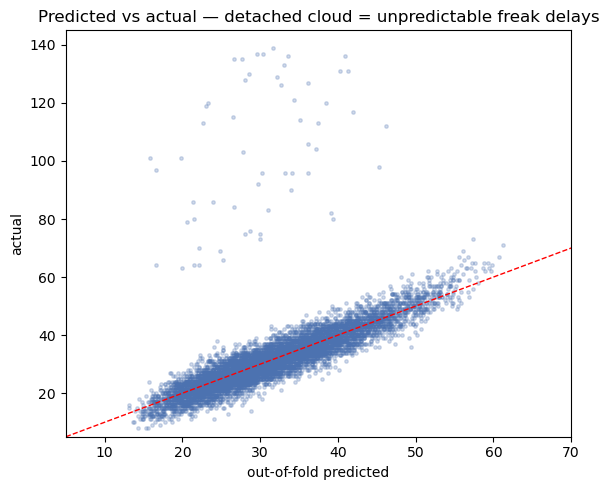

MAE by weather:
            mean  count
weather                
clear       3.29   4522
cloudy      2.96   1828
heavy_rain  3.82    411
rain        3.40   1011 

MAE by city_zone:
               mean  count
city_zone                 
downtown       3.22   2431
midtown        3.34   2185
suburbs_north  3.62    786
suburbs_south  3.14   1068
uptown         3.18   1530 

MAE by courier_vehicle:
                 mean  count
courier_vehicle             
bike             3.19   2567
car              3.53   2284
scooter          3.15   3149 

MAE by is_rush:
         mean  count
is_rush             
0        3.22   2820
1        3.30   5180 

MAE on normal orders (<=60): 2.75 min | on freak orders (>60): 49.68 min
freak orders are 1.1% of orders but 17% of total absolute error


,order_id,actual,predicted,abs_error
976,701213,135.0,26.633519,108.366481
1934,702403,137.0,29.592843,107.407157
5416,706774,135.0,27.643651,107.356349
4107,705101,139.0,31.700098,107.299902
5677,707105,137.0,30.361548,106.638452
4904,706112,136.0,33.598841,102.401159
3793,704718,130.0,28.620496,101.379504
3197,703973,128.0,28.010093,99.989907
2637,703263,133.0,33.047016,99.952984
858,701076,129.0,32.161017,96.838983


In [11]:
oof_df = pd.DataFrame({"order_id": train.order_id, "actual": y,
                       "predicted": oof["HistGradientBoosting"]})
oof_df["abs_error"] = (oof_df.actual - oof_df.predicted).abs()
plt.figure(figsize=(6,5)); plt.scatter(oof_df.predicted, oof_df.actual, s=6, alpha=.25, color="#4C72B0")
plt.plot([5,145],[5,145], "r--", lw=1); plt.xlim(5,70); plt.ylim(5,145)
plt.xlabel("out-of-fold predicted"); plt.ylabel("actual")
plt.title("Predicted vs actual — detached cloud = unpredictable freak delays"); plt.tight_layout(); plt.show()
seg = train_f.assign(abs_err=oof_df.abs_error.values)
for col in ["weather", "city_zone", "courier_vehicle", "is_rush"]:
    print(f"MAE by {col}:"); print(seg.groupby(col).abs_err.agg(["mean","count"]).round(2).to_string(), "\n")
normal, freak = seg[seg.delivery_minutes<=TARGET_CAP], seg[seg.delivery_minutes>TARGET_CAP]
print(f"MAE on normal orders (<=60): {normal.abs_err.mean():.2f} min | on freak orders (>60): {freak.abs_err.mean():.2f} min")
print(f"freak orders are {(len(freak)/len(seg))*100:.1f}% of orders but {freak.abs_err.sum()/seg.abs_err.sum()*100:.0f}% of total absolute error")
oof_df.nlargest(10, "abs_error")

## 8. Enhancements — from a prediction to a product

Four upgrades were tested. Three earn their place as *companion* outputs (they don't change the point predictions in `predictions.csv`); one is honestly rejected.

### 8a. Quantile model — quote a promise, not an average

The MAE model predicts the *typical* time, so by construction ~half of customers get their food later than quoted. A customer-facing ETA should be conservative: train the same HistGradientBoosting with a quantile loss at the 75th percentile and judge it by **coverage** — the share of deliveries that actually arrive by the quoted time (target ≈75%) — plus pinball loss. It is trained on the *uncapped* target, because the promise must respect the real tail.

 quantile  coverage % (actual <= quoted)  mean quoted (min)  pinball loss  MAE if used as point pred
     0.50                           50.3               31.5          1.63                       3.27
     0.75                           73.3               33.7          1.48                       3.77


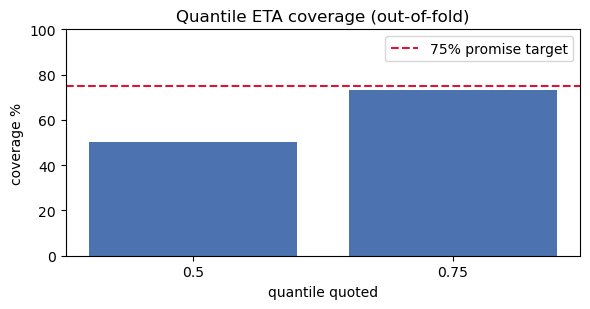

In [12]:
def make_quantile(q):
    return Pipeline([("pre", make_pre()), ("m", HistGradientBoostingRegressor(
        loss="quantile", quantile=q, learning_rate=0.03, max_iter=300, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE))])
def pinball(y_true, pred, q): return float(np.mean(np.maximum(q*(y_true-pred), (q-1)*(y_true-pred))))
q_rows = []
for q in [0.50, 0.75]:
    qp = np.clip(cross_val_predict(make_quantile(q), X, y, cv=kf), 8, None)  # NOTE: uncapped y
    q_rows.append({"quantile": q, "coverage % (actual <= quoted)": round((y <= qp).mean()*100, 1),
                   "mean quoted (min)": round(qp.mean(), 1), "pinball loss": round(pinball(y, qp, q), 2),
                   "MAE if used as point pred": round(mean_absolute_error(y, qp), 2)})
qres = pd.DataFrame(q_rows); print(qres.to_string(index=False))
plt.figure(figsize=(6,3.2)); plt.bar(qres["quantile"].astype(str), qres["coverage % (actual <= quoted)"], color="#4C72B0")
plt.axhline(75, color="crimson", ls="--", label="75% promise target"); plt.ylim(0,100)
plt.ylabel("coverage %"); plt.xlabel("quantile quoted"); plt.legend(); plt.title("Quantile ETA coverage (out-of-fold)"); plt.tight_layout(); plt.show()

The 75th-percentile model covers ~73% of deliveries out-of-fold (target 75%) while quoting only ~1.7 min above the average actual time — a cheap promise to keep. Its MAE (3.77) is worse than the point model's, as expected: it is deliberately biased upward. **Use the MAE model internally, the q75 model on the customer screen.**

### 8b. Very-late-risk classifier — flag orders before they go wrong

A second, classification model predicts P(delivery > 45 min) (base rate 8.3%). Operations can act on a high flag at placement time: upgrade bike → scooter/car, prioritise the order, or warn the customer early. Judged by ROC-AUC / PR-AUC and precision/recall at usable thresholds, not accuracy.

late base rate 8.3% | ROC-AUC = 0.934 | PR-AUC = 0.774
threshold 0.3: precision 0.714 | recall 0.718 | flags 8.4% of orders
threshold 0.5: precision 0.794 | recall 0.598 | flags 6.3% of orders
threshold 0.7: precision 0.864 | recall 0.495 | flags 4.8% of orders


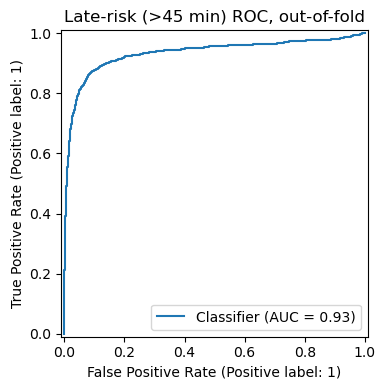

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, RocCurveDisplay
late = (y > 45).astype(int)
clf = Pipeline([("pre", make_pre()), ("m", HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=300, max_leaf_nodes=15, random_state=RANDOM_STATE))])
proba = cross_val_predict(clf, X, late, cv=kf, method="predict_proba")[:, 1]
print(f"late base rate {late.mean()*100:.1f}% | ROC-AUC = {roc_auc_score(late, proba):.3f} | PR-AUC = {average_precision_score(late, proba):.3f}")
for th in [0.3, 0.5, 0.7]:
    flag = (proba >= th).astype(int)
    print(f"threshold {th}: precision {precision_score(late, flag):.3f} | recall {recall_score(late, flag):.3f} | flags {flag.mean()*100:.1f}% of orders")
fig, ax = plt.subplots(figsize=(5,4)); RocCurveDisplay.from_predictions(late, proba, ax=ax); plt.title("Late-risk (>45 min) ROC, out-of-fold"); plt.tight_layout(); plt.show()

ROC-AUC ≈ 0.93: lateness is far more predictable than the freak tail suggested, because >45 min is mostly driven by observable load (long distance + slow kitchen + rush + rain). At threshold 0.5 it flags ~6% of orders and is right ~79% of the time while catching ~60% of all very-late orders — a usable operating point for proactive intervention.

### 8c. SHAP — explain individual predictions

Permutation importance (Section 6) ranks features globally; SHAP attributes each *individual* prediction, which is what a product team needs ("why is *this* ETA 41 min?"). Applied to the Section-6 model on held-out orders (features after the pipeline's encoding, hence names like `cat__courier_vehicle_bike`).

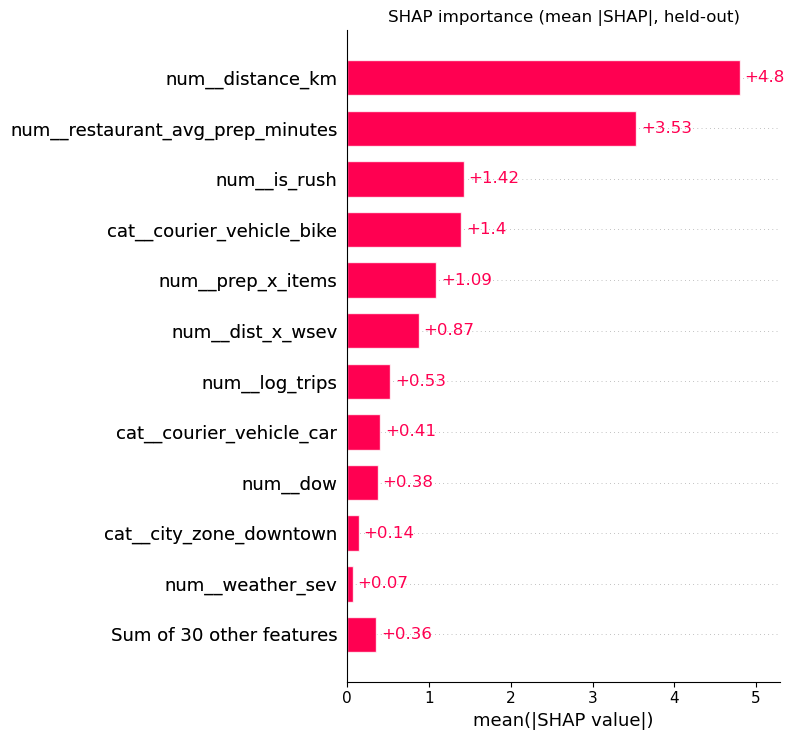

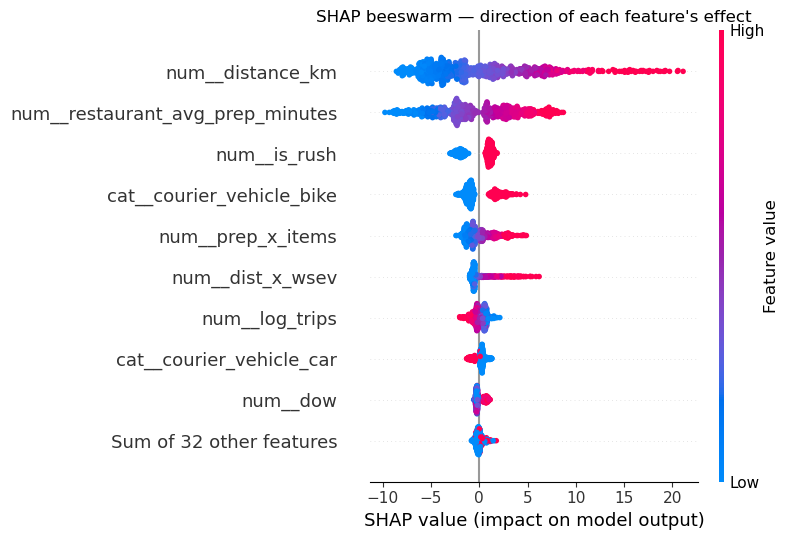

Top SHAP features:
num__distance_km                    4.80
num__restaurant_avg_prep_minutes    3.53
num__is_rush                        1.42
cat__courier_vehicle_bike           1.40
num__prep_x_items                   1.09
num__dist_x_wsev                    0.87
num__log_trips                      0.53
cat__courier_vehicle_car            0.41
num__dow                            0.38
cat__city_zone_downtown             0.14


In [14]:
import shap
sample_va = X_va.sample(800, random_state=0)
X_enc = model.named_steps["pre"].transform(sample_va)
feat_names = list(model.named_steps["pre"].get_feature_names_out())
explainer = shap.TreeExplainer(model.named_steps["m"])
sv = explainer.shap_values(X_enc)
shap_exp = shap.Explanation(values=sv, base_values=explainer.expected_value, data=X_enc, feature_names=feat_names)
shap.plots.bar(shap_exp, max_display=12, show=False); plt.title("SHAP importance (mean |SHAP|, held-out)"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(shap_exp, max_display=10, show=False); plt.title("SHAP beeswarm — direction of each feature's effect"); plt.tight_layout(); plt.show()
top_shap = pd.Series(np.abs(sv).mean(0), index=feat_names).sort_values(ascending=False).head(10)
print("Top SHAP features:"); print(top_shap.round(2).to_string())

SHAP agrees with permutation importance (distance ≫ prep time, then rush/bike/prep×items), which strengthens confidence in both. The beeswarm adds direction: high distance and high prep push predictions up (red on the right), experienced couriers pull them down.

### 8d. Restaurant target encoding — tested, and rejected

Section 2 excluded `restaurant_id` because it duplicates cuisine/zone/prep. But a restaurant's *historical average outcome* might still capture kitchen-specific slowness beyond its stated prep time. Tested properly — smoothed (m=10) out-of-fold encoding computed **inside** each outer training fold, so no label leakage — does it beat 3.271?

In [15]:
def add_rest_encoding(X_part, enc_map, global_mean):
    out = X_part.copy(); out["rest_hist_mean"] = out_restaurant.map(enc_map).fillna(global_mean).values; return out
NUM_TE = NUM + ["rest_hist_mean"]
def make_pre_te():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_TE),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
out_restaurant = train_f["restaurant_id"]
te_pred = np.zeros_like(y)
for tr_idx, va_idx in kf.split(X):
    gm = y_train[tr_idx].mean()
    stats = pd.DataFrame({"r": out_restaurant.iloc[tr_idx], "y": y_train[tr_idx]}).groupby("r")["y"].agg(["mean","count"])
    enc_map = (stats["mean"]*stats["count"] + gm*10) / (stats["count"] + 10)
    # OOF encoding for the training rows themselves (inner 5-fold) to avoid self-leakage
    enc_tr = np.full(len(tr_idx), gm); inner = KFold(5, shuffle=True, random_state=1); pos = np.arange(len(tr_idx))
    for itr, iva in inner.split(pos):
        s2 = pd.DataFrame({"r": out_restaurant.iloc[tr_idx].iloc[itr], "y": y_train[tr_idx][itr]}).groupby("r")["y"].agg(["mean","count"])
        m2 = (s2["mean"]*s2["count"] + gm*10) / (s2["count"] + 10)
        enc_tr[iva] = out_restaurant.iloc[tr_idx].iloc[iva].map(m2).fillna(gm).values
    Xtr = X.iloc[tr_idx].copy(); Xtr["rest_hist_mean"] = enc_tr
    Xva = X.iloc[va_idx].copy();  Xva["rest_hist_mean"] = out_restaurant.iloc[va_idx].map(enc_map).fillna(gm).values
    mm = Pipeline([("pre", make_pre_te()), ("m", HistGradientBoostingRegressor(
        learning_rate=0.03, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0, random_state=RANDOM_STATE))])
    mm.fit(Xtr, y_train[tr_idx]); te_pred[va_idx] = np.clip(mm.predict(Xva), 8, None)
print(f"HistGB + OOF restaurant target encoding: CV MAE = {mean_absolute_error(y, te_pred):.3f}  vs plain HistGB 3.271")
print("Verdict:", "KEEP" if mean_absolute_error(y, te_pred) < 3.271 else "REJECTED - encoding adds nothing beyond prep/cuisine/zone, so the point model and predictions.csv stay unchanged")

HistGB + OOF restaurant target encoding: CV MAE = 3.299  vs plain HistGB 3.271
Verdict: REJECTED - encoding adds nothing beyond prep/cuisine/zone, so the point model and predictions.csv stay unchanged


**Enhancement verdicts**

| Enhancement | Result | Decision |
|---|---|---|
| Quantile (q75) promise model | ~73% coverage at +1.7 min average quote | **Adopt** for customer-facing ETA |
| Late-risk classifier (>45 min) | ROC-AUC ≈0.93; @0.5: 79% precision, 60% recall | **Adopt** as an operations flag |
| SHAP explanations | Agrees with permutation ranking; gives per-order reasons | **Adopt** for interpretability |
| Restaurant target encoding | CV MAE 3.30 vs 3.27 without | **Rejected** — reported, not shipped |
| Streamlit demo | `app.py` in this repo: enter an order → typical ETA, q75 promise, late-risk, top reasons | **Adopt** for demoing |

The point model — and therefore `predictions.csv` — is unchanged: none of the enhancements beat it at its own job, and that is the honest outcome.

The 10 worst errors (97–108 min, all *under*-predictions, e.g. predicted 26.6 vs actual 135) are exactly the Section-2 freak tail — no placement-time feature warns about them. Elsewhere the error is even (MAE ≈3.0–3.8; worst segment: heavy rain). **Product implication:** this model is a good *typical* ETA but cannot foresee freak delays — for the customer promise, quote a high quantile (e.g. a 75th-percentile model) or add buffer for heavy-rain/rush/long-distance orders, and treat "very late" as a separate risk-classification problem.

## 9. Predict the test set

In [16]:
final = make_models()["HistGradientBoosting"].fit(X, y_train)
pred = np.clip(final.predict(X_test), 8, 65)
predictions = pd.DataFrame({"order_id": test.order_id, "predicted_minutes": np.round(pred, 2)})
assert predictions.shape[0] == len(test) and predictions.predicted_minutes.notna().all()
assert set(predictions.order_id) == set(test.order_id) and not predictions.order_id.duplicated().any()
predictions.to_csv("predictions.csv", index=False)
print(f"predictions.csv saved: {len(predictions)} rows | range "
      f"[{predictions.predicted_minutes.min()}, {predictions.predicted_minutes.max()}] | "
      f"mean {predictions.predicted_minutes.mean():.2f} (train mean {y.mean():.2f})")
predictions.head()

predictions.csv saved: 2000 rows | range [13.49, 63.05] | mean 31.59 (train mean 32.05)


,order_id,predicted_minutes
0,700002,30.54
1,700007,30.85
2,700013,52.82
3,700029,30.33
4,700030,32.34


## 10. Conclusions & limitations

- A gradient-boosting model on placement-time features cuts ETA error from 7.73 → **3.27 min MAE** (typical error ~2.8 min on normal orders); delivery slowness is physical and mostly additive: **distance, kitchen prep time, vehicle, rush hour, rain, basket size** — in that order.
- The deliverable is now a small system, not a single number: **MAE model** for internal planning, **q75 quantile model** (~73% coverage) for the customer promise, **late-risk classifier** (AUC ≈0.93) for operations, and **SHAP** reasons per order — demoable live via `app.py` (Streamlit).
- An honest negative result is kept in the record: restaurant target encoding, tested leakage-safely, does **not** help (3.30 vs 3.27).
- **Limitations:** (1) weather is as recorded at placement — in production only a forecast would be available; (2) no live signals (restaurant's current load, courier's in-flight orders, traffic) — the biggest realistic lever for further gains; (3) the ~1% freak delays remain unforeseeable, which is precisely why the promise is a quantile, not the mean estimate; (4) validation is within Mar–Aug 2025, so monitor for seasonal drift.